In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
plt.style.use('ggplot')

In [3]:
df = pd.read_csv("/content/laptopData.csv")

# step 1: data understanding

In [4]:
df.shape

(1303, 12)

In [5]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [6]:
df.columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')

In [7]:
df.dtypes

,0
Unnamed: 0,float64
Company,object
TypeName,object
Inches,object
ScreenResolution,object
Cpu,object
Ram,object
Memory,object
Gpu,object
OpSys,object


(Company, TypeName, Cpu, Memory, Gpu, OpSys, ScreenResolution)

(Categorical).


Unnamed: 0
Inches (مفروض رقم)
Weight (مفروض رقم)
Ram ( تحويلها من نص إلى رقم لان فيها GB)

In [8]:
df.describe()

,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [9]:
df['OpSys'].unique()

array(['macOS', 'No OS', 'Windows 10', 'Mac OS X', nan, 'Linux',
       'Windows 10 S', 'Chrome OS', 'Windows 7', 'Android'], dtype=object)

# EDA (تحليل استكشافي أولي — قبل التنظيف)

أسوي هنا نظرة أولية على البيانات الخام قبل لا أبدأ التنظيف والهندسة، عشان أفهم شكل التوزيعات والعلاقات الأساسية من البداية. بعض الرسومات (زي الـ correlation heatmap وتوزيع CPU) تحتاج أعمدة رقمية مو موجودة إلا بعد التنظيف والهندسة، فهذي موجودة تحت في قسم EDA الموسّع.

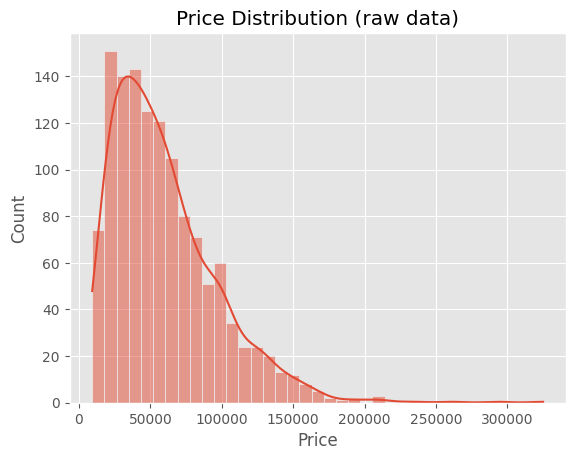

In [10]:
sns.histplot(df["Price"], kde=True)
plt.title("Price Distribution (raw data)")
plt.show()

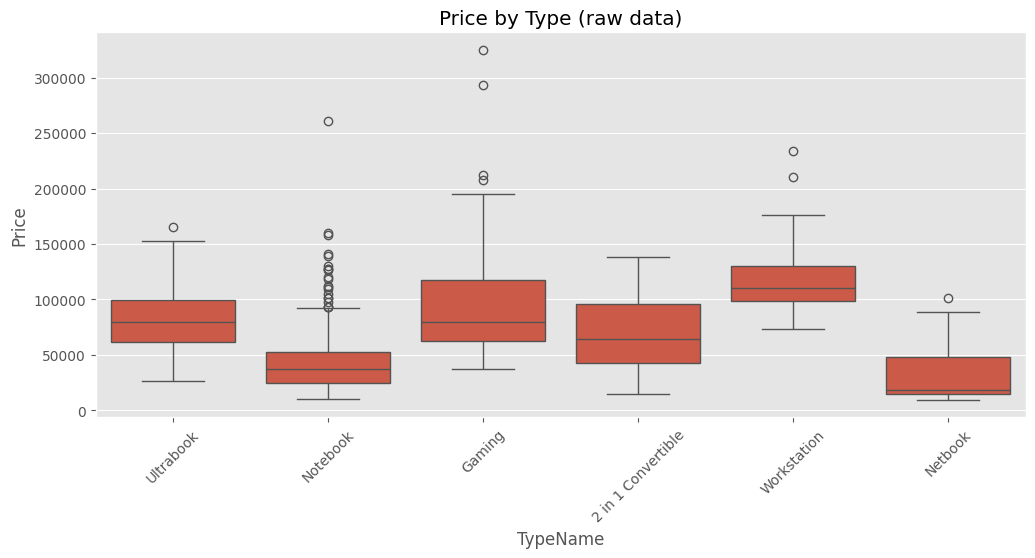

In [11]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="TypeName", y="Price")
plt.xticks(rotation=45)
plt.title("Price by Type (raw data)")
plt.show()

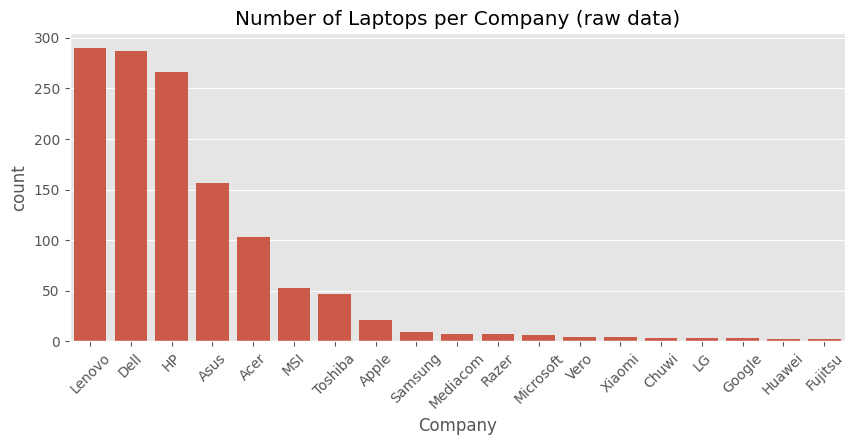

In [12]:
plt.figure(figsize=(10,4))
sns.countplot(x="Company", data=df, order=df["Company"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Number of Laptops per Company (raw data)")
plt.show()

# step 2: data preparation

In [13]:
df = df.drop(['Unnamed: 0'], axis=1)

حذفت هذا العمود لان ماله داعي هو بس رقم السطر و ايضا لازم اكتب
axis=1
عشان يعرف انحه ما يحذف سطر لا يحذف عامود

 أفحص كل الأعمدة مرة وحدة عن '؟' بدل ما أفحص عمود عمود، عشان لو فيه عمود نسيته يدوي

In [14]:
(df == '?').sum()

,0
Company,0
TypeName,0
Inches,1
ScreenResolution,0
Cpu,0
Ram,0
Memory,1
Gpu,0
OpSys,0
Weight,1


In [15]:
df.shape

(1303, 11)

لازم اسوي فيتشر جديده ل التخزين واخليها بس ارقام

لازم احذف القيم الغير منطقيه في كل الداتا سيت والقيم الفارغه

In [16]:
df.isna().sum()

,0
Company,30
TypeName,30
Inches,30
ScreenResolution,30
Cpu,30
Ram,30
Memory,30
Gpu,30
OpSys,30
Weight,30


In [17]:
df.isnull().sum().sum()

np.int64(330)

In [18]:
df = df.dropna()

In [19]:
df.duplicated().sum()

np.int64(29)

In [20]:
df[df.duplicated()]

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1274,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1275,Asus,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz,8GB,512GB SSD,Intel HD Graphics 515,Windows 10,1.2kg,38841.1200
1276,Dell,Notebook,15.6,1366x768,Intel Core i3 7100U 2.4GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows 10,2.3kg,24455.5200
1277,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.9200
1278,Dell,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,500GB HDD,Intel HD Graphics,Windows 10,2.20kg,20193.1200
1279,Lenovo,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,8GB,1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.6kg,47898.7200
1280,HP,Notebook,15.6,Full HD 1920x1080,AMD A9-Series 9410 2.9GHz,6GB,1.0TB Hybrid,AMD Radeon R7 M440,Windows 10,2.04kg,29303.4672
1281,Dell,Notebook,15.6,1366x768,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R5 M430,Linux,2.3kg,42943.1472
1282,HP,Netbook,11.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,2GB,32GB Flash Storage,Intel HD Graphics 400,Windows 10,1.17kg,11135.5200
1283,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4GB,500GB HDD,Nvidia GeForce 920M,Windows 10,2.2kg,38378.6496


In [21]:
df.loc[1302].equals(df.loc[1288])

True

In [22]:
df = df.drop_duplicates()

In [23]:
df.isnull().sum().sum()

np.int64(0)

**تبرير استراتيجية التنظيف**

* حذفت الصفوف اللي كل قيمها فاضية وعددها 30 صف لأنها ما تعطي أي معلومة ومستحيل أعوضها.

* حذفت الصفوف المكررة لأنها تمثل نفس اللابتوب مكرر بالضبط وتأكدت باستخدام `df.loc[1302].equals(df.loc[1288])`

 فتكرارها بس يزيد وزنها في التدريب بدون أي فائدة.

* بالنسبة لبقية القيم الناقصة مثل Weight و Memory بستخدم **Median** بدل **Mean** لأن الـ Median أقل تأثر بالـ Outliers. وبما إن عندنا قيم متطرفة في الأوزان وأحجام التخزين فالـ Mean راح يتأثر بهالقيم بينما الـ Median يعطيني قيمة أوسط وأكثر واقعية.


# تقسيم الاعمده

# ScreenResolution

١ لمس ولا مولمس
٢-اي بي اس ولا لا
 ٣- حجم الشاشه
٤- اذا اتش دي ولالا

In [24]:
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)

1 = Touchscreen
0 = No Touchscreen

In [25]:
df["IPS"]=df["ScreenResolution"].str.contains("IPS").astype(int)

1 = IPS Panel.
0 = NO IPS.

In [26]:
df["Resolution"] = df["ScreenResolution"].str.split().str[-1]

هنا راح ياخذ اخر سترينق من كل عامود وراح يحفظه في عامود لحاله

In [27]:
df[["Resolution_X", "Resolution_Y"]] = df["Resolution"].str.split("x", expand=True)# افصلها إلى أعمدة ما ابغا ليست

In [28]:
print(df[["Resolution_X", "Resolution_Y"]])

     Resolution_X Resolution_Y
0            2560         1600
1            1440          900
2            1920         1080
3            2880         1800
4            2560         1600
...           ...          ...
1269         1366          768
1270         1920         1080
1271         3200         1800
1272         1366          768
1273         1366          768

[1244 rows x 2 columns]


In [29]:
df[["Resolution_X", "Resolution_Y"]]=df[["Resolution_X", "Resolution_Y"]].astype(int)

In [30]:
df["ScreenSize"]=df["Resolution_X"] * df["Resolution_Y"].astype(int)

In [31]:
print(df["ScreenSize"])

0       4096000
1       1296000
2       2073600
3       5184000
4       4096000
         ...   
1269    1049088
1270    2073600
1271    5760000
1272    1049088
1273    1049088
Name: ScreenSize, Length: 1244, dtype: int64


In [32]:
df["UltraHD"]=df["ScreenResolution"].str.contains("4K").astype(int)

شفت البيانات اذا الترا يكون موجود ٤كي لازم بس بعض الاحيان ما يكتب الترا اتش دي ف عشان كذا خليتها اذا فيها ٤ كي

In [33]:
df["FullHD"]=df["ScreenResolution"].str.contains("Full").astype(int)

In [34]:
df["Quad"]=df["ScreenResolution"].str.contains("Quad").astype(int)

# Inches

In [35]:
print(df.iloc[465])

Company                                    Dell
TypeName                            Workstation
Inches                                        ?
ScreenResolution              Full HD 1920x1080
Cpu                 Intel Core i7 7700HQ 2.8GHz
Ram                                         8GB
Memory                                256GB SSD
Gpu                         Nvidia Quadro M1200
OpSys                                Windows 10
Weight                                   1.78kg
Price                                 128298.24
Touchscreen                                   0
IPS                                           0
Resolution                            1920x1080
Resolution_X                               1920
Resolution_Y                               1080
ScreenSize                              2073600
UltraHD                                       0
FullHD                                        1
Quad                                          0
Name: 476, dtype: object


In [36]:
df['Inches'] = df['Inches'].replace('?', np.nan)

In [37]:
df['Inches'] = df['Inches'].astype(float)

In [38]:
df['Inches'] = df['Inches'].fillna(df['Inches'].median())

استخدمت median هنا بدل mean لنفس السبب اللي وضحته فوق - أقل حساسية للـ outliers.

In [39]:
print(df.iloc[465])

Company                                    Dell
TypeName                            Workstation
Inches                                     15.6
ScreenResolution              Full HD 1920x1080
Cpu                 Intel Core i7 7700HQ 2.8GHz
Ram                                         8GB
Memory                                256GB SSD
Gpu                         Nvidia Quadro M1200
OpSys                                Windows 10
Weight                                   1.78kg
Price                                 128298.24
Touchscreen                                   0
IPS                                           0
Resolution                            1920x1080
Resolution_X                               1920
Resolution_Y                               1080
ScreenSize                              2073600
UltraHD                                       0
FullHD                                        1
Quad                                          0
Name: 476, dtype: object


In [40]:
df['Inches'].unique()

array([13.3, 15.6, 15.4, 14. , 12. , 17.3, 13.5, 12.5, 13. , 18.4, 13.9,
       11.6, 25.6, 35.6, 12.3, 27.3, 24. , 33.5, 31.6, 17. , 15. , 14.1,
       11.3, 10.1])

In [41]:
df["Inches"].describe()

,Inches
count,1244.000000
mean,15.139228
std,1.966634
min,10.100000
25%,14.000000
50%,15.600000
75%,15.600000
max,35.600000


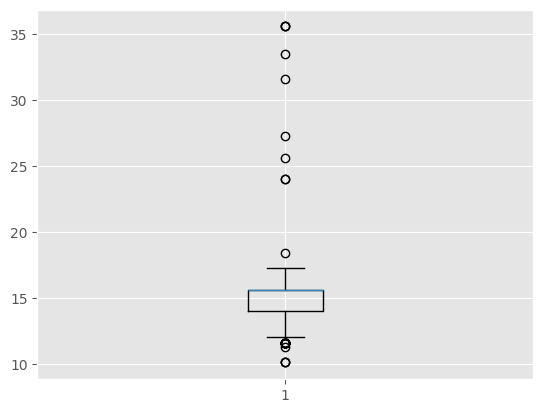

In [42]:
plt.boxplot(df["Inches"])
plt.show()

In [43]:
# Check for unrealistic screen sizes
df[(df["Inches"] < 10) | (df["Inches"] > 19)]

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
402,Lenovo,Notebook,25.6,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD + 1TB HDD,AMD Radeon RX 550,Windows 10,2.1kg,60978.96,0,1,1920x1080,1920,1080,2073600,0,1,0
408,Lenovo,Notebook,35.6,Full HD 1920x1080,Intel Core i3 6006U 2GHz,4GB,500GB HDD,Intel HD Graphics 520,Windows 10,2.2kg,21791.52,0,0,1920x1080,1920,1080,2073600,0,1,0
423,Asus,Notebook,35.6,Full HD 1920x1080,Intel Core i3 7100U 2.4GHz,8GB,1TB HDD,Nvidia GeForce 940MX,Linux,2.3kg,31808.16,0,0,1920x1080,1920,1080,2073600,0,1,0
424,Dell,Gaming,27.3,IPS Panel 2560x1440,Intel Core i7 7820HK 2.9GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,149130.72,0,1,2560x1440,2560,1440,3686400,0,0,0
438,Lenovo,Ultrabook,24.0,2560x1440,Intel Core i7 7500U 2.7GHz,24GB,512GB SSD,Intel HD Graphics 620,Windows 10,1.32kg,126912.96,0,0,2560x1440,2560,1440,3686400,0,0,0
458,Microsoft,Ultrabook,33.5,Touchscreen 2256x1504,Intel Core i7 7660U 2.5GHz,8GB,256GB SSD,Intel Iris Plus Graphics 640,Windows 10 S,1.25kg,95850.72,1,0,2256x1504,2256,1504,3393024,0,0,0
525,Lenovo,Notebook,24.0,Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,2.02kg,71395.20,0,0,1920x1080,1920,1080,2073600,0,1,0
592,Dell,2 in 1 Convertible,31.6,Touchscreen 1366x768,Intel Core M 7Y30 1.0GHz,4GB,128GB SSD,Intel HD Graphics 615,Windows 10,1.39kg,32127.84,1,0,1366x768,1366,768,1049088,0,0,0
673,Lenovo,Notebook,35.6,1366x768,AMD E-Series E2-9000 2.2GHz,4GB,128GB SSD,AMD Radeon R2 Graphics,Windows 10,2.2kg,18594.72,0,0,1366x768,1366,768,1049088,0,0,0


الشركات اللي فيها اوتلايرز
Lenovo ، Dell، Microsoft، Asus،

In [44]:
df[df['Company']=='Asus']
# ابغا اقارن القيم الغير منطقيه اللي طلعت لي فوق و القيم اللي موجوده بالشركه
#عشان اعرف نوع الخطا ر

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
8,Asus,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows 10,1.3kg,79653.6000,0,0,1920x1080,1920,1080,2073600,0,1,0
31,Asus,Notebook,14.0,1366x768,AMD E-Series E2-6110 1.5GHz,2GB,32GB Flash Storage,AMD Radeon R2,Windows 10,1.65kg,10602.7200,0,0,1366x768,1366,768,1049088,0,0,0
40,Asus,Notebook,15.6,Full HD 1920x1080,Intel Core i3 6006U 2GHz,4GB,1TB HDD,Intel HD Graphics 620,Linux,2kg,20725.9200,0,0,1920x1080,1920,1080,2073600,0,1,0
42,Asus,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,8GB,1TB HDD,Nvidia GeForce 940MX,Linux,2.3kg,27864.9072,0,0,1366x768,1366,768,1049088,0,0,0
47,Asus,Gaming,17.3,Full HD 1920x1080,AMD Ryzen 1700 3GHz,8GB,256GB SSD + 1TB HDD,AMD Radeon RX 580,Windows 10,3.2kg,69210.7200,0,0,1920x1080,1920,1080,2073600,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1247,Asus,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,2.34kg,123876.0000,0,1,1920x1080,1920,1080,2073600,0,1,0
1255,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3350 1.1GHz,4GB,1TB HDD,Intel HD Graphics 500,Windows 10,2kg,18061.9200,0,0,1366x768,1366,768,1049088,0,0,0
1256,Asus,Gaming,17.3,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,16GB,128GB SSD + 1TB HDD,Nvidia GeForce GTX 970M,Windows 10,4.0kg,101232.0000,0,1,1920x1080,1920,1080,2073600,0,1,0
1261,Asus,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz,8GB,512GB SSD,Intel HD Graphics 515,Windows 10,1.2kg,38841.1200,0,1,1920x1080,1920,1080,2073600,0,1,0


الواضح انه قيمة ٣٥.٦ خطا في الكتابه بدل ١٥.٦ حط ٣ بدل الواحد

In [45]:
df['Inches'] = df['Inches'].replace(35.6, 15.6)

In [46]:
df[(df["Inches"] < 10) | (df["Inches"] > 19)]

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
402,Lenovo,Notebook,25.6,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD + 1TB HDD,AMD Radeon RX 550,Windows 10,2.1kg,60978.96,0,1,1920x1080,1920,1080,2073600,0,1,0
424,Dell,Gaming,27.3,IPS Panel 2560x1440,Intel Core i7 7820HK 2.9GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,149130.72,0,1,2560x1440,2560,1440,3686400,0,0,0
438,Lenovo,Ultrabook,24.0,2560x1440,Intel Core i7 7500U 2.7GHz,24GB,512GB SSD,Intel HD Graphics 620,Windows 10,1.32kg,126912.96,0,0,2560x1440,2560,1440,3686400,0,0,0
458,Microsoft,Ultrabook,33.5,Touchscreen 2256x1504,Intel Core i7 7660U 2.5GHz,8GB,256GB SSD,Intel Iris Plus Graphics 640,Windows 10 S,1.25kg,95850.72,1,0,2256x1504,2256,1504,3393024,0,0,0
525,Lenovo,Notebook,24.0,Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,2.02kg,71395.20,0,0,1920x1080,1920,1080,2073600,0,1,0
592,Dell,2 in 1 Convertible,31.6,Touchscreen 1366x768,Intel Core M 7Y30 1.0GHz,4GB,128GB SSD,Intel HD Graphics 615,Windows 10,1.39kg,32127.84,1,0,1366x768,1366,768,1049088,0,0,0


In [47]:
df[df['Company']=='Dell']

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
13,Dell,Notebook,15.6,Full HD 1920x1080,Intel Core i3 6006U 2GHz,4GB,256GB SSD,AMD Radeon R5 M430,Windows 10,2.2kg,26581.3920,0,0,1920x1080,1920,1080,2073600,0,1,0
16,Dell,Notebook,15.6,Full HD 1920x1080,Intel Core i7 7500U 2.7GHz,8GB,256GB SSD,AMD Radeon R5 M430,Windows 10,2.2kg,39693.6000,0,0,1920x1080,1920,1080,2073600,0,1,0
19,Dell,Ultrabook,13.3,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,128GB SSD,Intel UHD Graphics 620,Windows 10,1.22kg,52161.1200,1,1,1920x1080,1920,1080,2073600,0,1,0
23,Dell,2 in 1 Convertible,13.3,Full HD / Touchscreen 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows 10,1.62kg,43636.3200,1,0,1920x1080,1920,1080,2073600,0,1,0
25,Dell,Notebook,15.6,1366x768,Intel Core i3 6006U 2GHz,4GB,1TB HDD,Intel HD Graphics 520,Windows 10,2.3kg,22305.1392,0,0,1366x768,1366,768,1049088,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1254,Dell,Notebook,15.6,1366x768,Intel Pentium Quad Core N3700 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,23655.7872,0,0,1366x768,1366,768,1049088,0,0,0
1257,Dell,Notebook,15.6,1366x768,Intel Core i3 6006U 2GHz,4GB,500GB HDD,Intel HD Graphics 520,Windows 10,2.29kg,26107.2000,0,0,1366x768,1366,768,1049088,0,0,0
1262,Dell,Notebook,15.6,1366x768,Intel Core i3 7100U 2.4GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows 10,2.3kg,24455.5200,0,0,1366x768,1366,768,1049088,0,0,0
1264,Dell,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,500GB HDD,Intel HD Graphics,Windows 10,2.20kg,20193.1200,0,0,1366x768,1366,768,1049088,0,0,0


In [48]:
df['Inches'] = df['Inches'].replace(27.3, 17.3)

In [49]:
df['Inches'] = df['Inches'].replace(31.6, 11.6)

لمن فتحت الداتا بنفسي و سويتها كا تيبل سوت سورت للشركه وسورت لقيم الانشز وطلع فيه  ٢٧ رو فيه ١٧.٣

فا استنتجت انه خطاء كتابه

In [50]:
df[df['Company']=='Lenovo']

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
18,Lenovo,Notebook,15.6,Full HD 1920x1080,Intel Core i3 7100U 2.4GHz,8GB,1TB HDD,Nvidia GeForce 940MX,No OS,2.2kg,26586.7200,0,0,1920x1080,1920,1080,2073600,0,1,0
21,Lenovo,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8GB,128GB SSD + 1TB HDD,Nvidia GeForce GTX 1050,Windows 10,2.5kg,53226.7200,0,1,1920x1080,1920,1080,2073600,0,1,0
35,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3350 1.1GHz,4GB,64GB Flash Storage,Intel HD Graphics 500,Windows 10,1.44kg,13266.7200,0,0,1366x768,1366,768,1049088,0,0,0
62,Lenovo,Notebook,14.0,IPS Panel Full HD 1920x1080,Intel Core i3 7130U 2.7GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.7kg,31914.7200,0,1,1920x1080,1920,1080,2073600,0,1,0
68,Lenovo,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,4GB,1TB HDD,Intel HD Graphics 620,Windows 10,1.9kg,29250.7200,0,0,1920x1080,1920,1080,2073600,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1260,Lenovo,2 in 1 Convertible,14.0,Full HD / Touchscreen 1920x1080,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,44382.7728,1,0,1920x1080,1920,1080,2073600,0,1,0
1265,Lenovo,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,8GB,1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.6kg,47898.7200,0,1,1920x1080,1920,1080,2073600,0,1,0
1270,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400,1,1,1920x1080,1920,1080,2073600,0,1,0
1271,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200,1,1,3200x1800,3200,1800,5760000,0,0,1


لاحظت ان فيه ١٥.٦
و ٢٥.٦ و ٣٥.٦ في الداتا فا اكيد انه خطا كتابي

In [51]:
df['Inches'] = df['Inches'].replace(25.6, 15.6)

In [52]:
df['Inches'] = df['Inches'].replace(35.6, 15.6)

In [53]:
df['Inches'] = df['Inches'].replace(24, 14)

In [54]:
df[df['Company']=='Microsoft']

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Touchscreen,IPS,Resolution,Resolution_X,Resolution_Y,ScreenSize,UltraHD,FullHD,Quad
70,Microsoft,Ultrabook,13.5,Touchscreen 2256x1504,Intel Core i5 7200U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 620,Windows 10 S,1.252kg,58021.920,1,0,2256x1504,2256,1504,3393024,0,0,0
104,Microsoft,Ultrabook,13.5,Touchscreen 2256x1504,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10 S,1.252kg,71395.200,1,0,2256x1504,2256,1504,3393024,0,0,0
449,Microsoft,Ultrabook,13.5,Touchscreen 2256x1504,Intel Core i7 7660U 2.5GHz,16GB,512GB SSD,Intel Iris Plus Graphics 640,Windows 10 S,1.25kg,137941.920,1,0,2256x1504,2256,1504,3393024,0,0,0
457,Microsoft,Ultrabook,13.5,Touchscreen 2256x1504,Intel Core M m3-7Y30 2.2GHz,4GB,128GB SSD,Intel HD Graphics 615,Windows 10 S,1.252kg,52693.920,1,0,2256x1504,2256,1504,3393024,0,0,0
458,Microsoft,Ultrabook,33.5,Touchscreen 2256x1504,Intel Core i7 7660U 2.5GHz,8GB,256GB SSD,Intel Iris Plus Graphics 640,Windows 10 S,1.25kg,95850.720,1,0,2256x1504,2256,1504,3393024,0,0,0
670,Microsoft,Ultrabook,13.5,Touchscreen 2256x1504,Intel Core i7 7600U 2.8GHz,8GB,256GB SSD,Intel Iris Plus Graphics 640,Windows 10 S,1.252kg,99519.048,1,0,2256x1504,2256,1504,3393024,0,0,0


مايكروسوفت مافيها الا ١٣،٥ و فجاه قيمه ٣٣،٥ فا اكيد انها خطا كتابه

In [55]:
df['Inches'] = df['Inches'].replace(33.5, 13.5)

احول الانشز من اوبجكت لفلوت

In [56]:
pd.to_numeric(df['Inches']).astype(float)

,Inches
0,13.3
1,13.3
2,15.6
3,15.4
4,13.3
...,...
1269,15.6
1270,14.0
1271,13.3
1272,14.0


# Cpu

فيه ثلاث معلومات
اسم الشركه

   (مو مهمه اعتقد)اسم المعالج


السرعه


In [57]:
df["CPU_Brand"]=df["Cpu"].str.split().str[0]

In [58]:
df["CPU_Speed"] = df["Cpu"].str.split().str[-1]

In [59]:
df["CPU_Speed"] = df["CPU_Speed"].str.replace("GHz", "").astype(float)

In [60]:
print(df["CPU_Speed"] )

0       2.3
1       1.8
2       2.5
3       2.7
4       3.1
       ... 
1269    2.5
1270    2.5
1271    2.5
1272    1.6
1273    2.5
Name: CPU_Speed, Length: 1244, dtype: float64


In [61]:
def cpu_category(cpu):
    cpu = cpu.lower()
    if 'core i7' in cpu:
        return 'Core i7'
    elif 'core i5' in cpu:
        return 'Core i5'
    elif 'core i3' in cpu:
        return 'Core i3'
    elif 'celeron' in cpu or 'pentium' in cpu or 'atom' in cpu:
        return 'Intel Basic'
    elif 'amd' in cpu:
        return 'AMD'
    else:
        return 'Other'   # Core M, Xeon, ARM

In [62]:
df["CPU_Name"] = df["Cpu"].apply(cpu_category)

In [63]:
print(df["CPU_Name"])

0           Core i5
1           Core i5
2           Core i5
3           Core i7
4           Core i5
           ...     
1269        Core i7
1270        Core i7
1271        Core i7
1272    Intel Basic
1273        Core i7
Name: CPU_Name, Length: 1244, dtype: object


# Ram

In [64]:
df['Ram'] = df['Ram'].str.replace('GB', '')

In [65]:
print(df['Ram'])

0        8
1        8
2        8
3       16
4        8
        ..
1269     4
1270     4
1271    16
1272     2
1273     6
Name: Ram, Length: 1244, dtype: object


In [66]:
df['Ram'] = df['Ram'].astype(int)

# Memory

In [67]:
df["Memory"] = df["Memory"].str.replace("2TB", "2048GB")
df["Memory"] = df["Memory"].str.replace("1TB", "1024GB")
df["Memory"] = df["Memory"].str.replace("1.0TB", "1024GB")

In [68]:
df["Memory"] = df["Memory"].replace("?", np.nan)

In [69]:
df["SSD"] = np.nan
df["HDD"] = np.nan
df["Flash"] = np.nan
df["Hybrid"] = np.nan

In [70]:
for i in df.index:

    if pd.isna(df.loc[i, "Memory"]):
        continue

    # نخلي القيمه المبدئية صفر
    df.loc[i, ["SSD", "HDD", "Flash", "Hybrid"]] = 0
    # نقسم العامود اذا فيه زائد
    parts = df.loc[i, "Memory"].split(" +  ")
    # لوب داخل البارتز
    for part in parts:
        # يجيب لي الارقام اللي قبل القيقا
        size = int(part.split("GB")[0])
        # اذا شاف ssd راح يدخل ويعطيها القيمه
        if "SSD" in part:
            df.loc[i, "SSD"] += size

        elif "HDD" in part:
            df.loc[i, "HDD"] += size

        elif "Flash" in part:
            df.loc[i, "Flash"] += size

        elif "Hybrid" in part:
            df.loc[i, "Hybrid"] += size

In [71]:
# Fill missing values
df["SSD"] = df["SSD"].fillna(df["SSD"].median())
df["HDD"] = df["HDD"].fillna(df["HDD"].median())
df["Flash"] = df["Flash"].fillna(df["Flash"].median())
df["Hybrid"] = df["Hybrid"].fillna(df["Hybrid"].median())

نفس المبدأ: median بدل mean عشان قيم التخزين (SSD/HDD) فيها تفاوت كبير بين اللابتوبات.

In [72]:
df[["SSD", "HDD", "Flash", "Hybrid"]].head()

,SSD,HDD,Flash,Hybrid
0,128.0,0.0,0.0,0.0
1,0.0,0.0,128.0,0.0
2,256.0,0.0,0.0,0.0
3,512.0,0.0,0.0,0.0
4,256.0,0.0,0.0,0.0


# GPU

In [73]:
df["GPU_Brand"] = df["Gpu"].str.split().str[0]

In [74]:
print(df["GPU_Brand"] )

0        Intel
1        Intel
2        Intel
3          AMD
4        Intel
         ...  
1269    Nvidia
1270     Intel
1271     Intel
1272     Intel
1273       AMD
Name: GPU_Brand, Length: 1244, dtype: object


# OpSys

In [75]:
df["OpSys"].value_counts()

,count
OpSys,
Windows 10,1022
No OS,63
Linux,57
Windows 7,45
Chrome OS,27
macOS,13
Mac OS X,8
Windows 10 S,8
Android,1


In [76]:
df["OpSys"] = df["OpSys"].replace({
    "Windows 10": "Windows",
    "Windows 7": "Windows",
    "Windows 10 S": "Windows",
    "Mac OS X": "Mac",
    "macOS": "Mac",
    "Android":"No OS"
})
#سويت زي كذا عشان النظام يكون واضح وما يعامل كل واحد على انه نظام لحاله


In [77]:
df["OpSys"].value_counts()

,count
OpSys,
Windows,1075
No OS,64
Linux,57
Chrome OS,27
Mac,21


# Weight

In [78]:
df["Weight"] = df["Weight"].replace("?",np.nan)

In [79]:
df["Weight"] = df["Weight"].str.replace("kg","")

In [80]:
df["Weight"] = df["Weight"].astype(float)

In [81]:
df["Weight"] = df["Weight"].fillna(df["Weight"].median())

نفس الشي بالنسبة للوزن - median أفضل من mean هنا.

# Company

In [82]:
df["Company"].unique()

array(['Apple', 'HP', 'Acer', 'Asus', 'Dell', 'Lenovo', 'Chuwi', 'MSI',
       'Microsoft', 'Toshiba', 'Huawei', 'Xiaomi', 'Vero', 'Razer',
       'Mediacom', 'Samsung', 'Google', 'Fujitsu', 'LG'], dtype=object)

# TypeName

In [83]:
df["TypeName"].unique()

array(['Ultrabook', 'Notebook', 'Gaming', '2 in 1 Convertible',
       'Workstation', 'Netbook'], dtype=object)

# 3 EDA after feature engineering
هذا الجزء يكمل الـ EDA الأولي اللي سويته بالأول، بس هنا أقدر أستخدم أعمدة جديدة انولدت من الهندسة (زي CPU_Brand) وأسوي correlation heatmap لأن الأعمدة صارت رقمية.

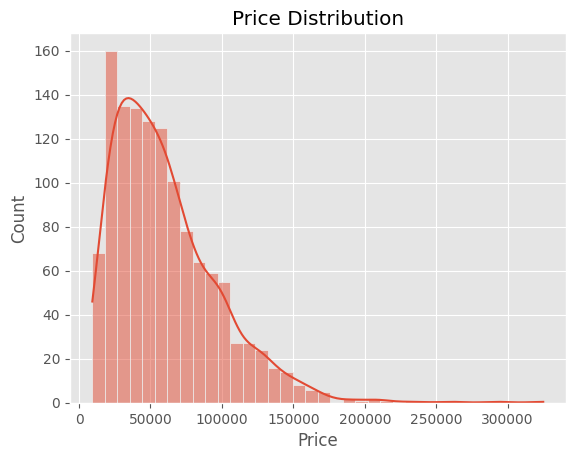

In [84]:
sns.histplot(df["Price"], kde=True)
plt.title("Price Distribution")
plt.show()

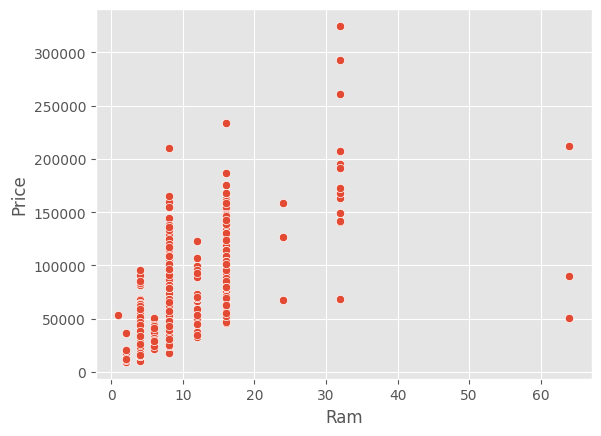

In [85]:
sns.scatterplot(data=df, x="Ram", y="Price")
plt.show()

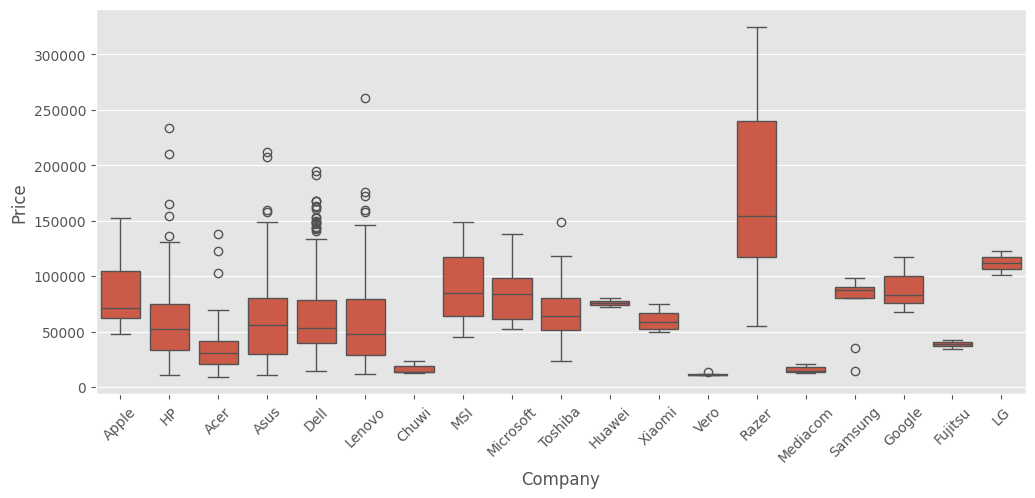

In [86]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x="Company", y="Price")
plt.xticks(rotation=45)
plt.show()

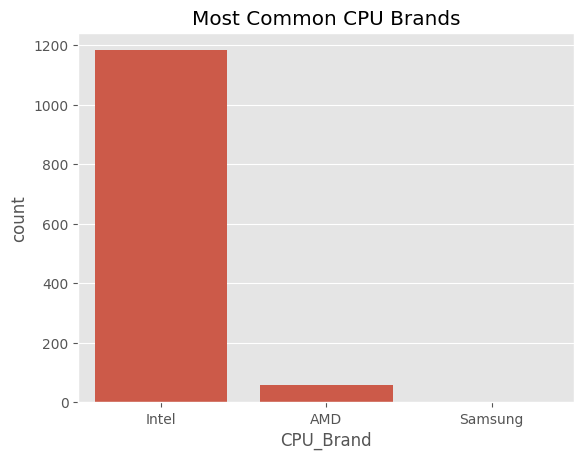

In [87]:
sns.countplot(x='CPU_Brand', data=df)
plt.title('Most Common CPU Brands')
plt.show()

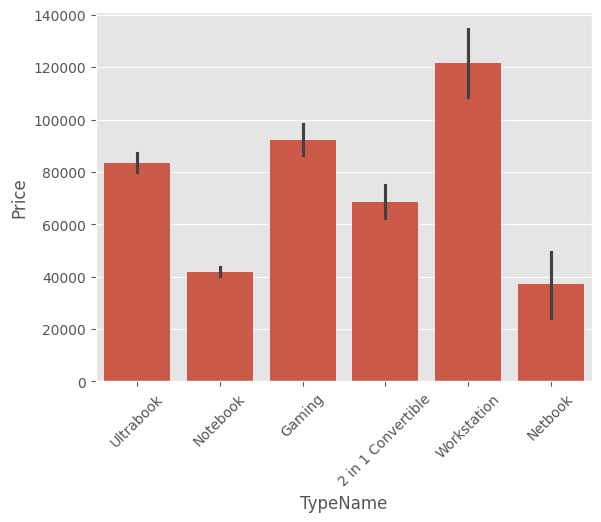

In [88]:
sns.barplot(x='TypeName', y='Price', data=df, estimator='mean')
plt.xticks(rotation=45)
plt.show()
#الخط الأسود فوق كل عمود يبين  مدى الثقة في رقم المتوسط

#خط قصير = عشان البيانات كثيرة → واثقين من المتوسط

#خط طويل = عشان البيانات قليلة → مو متأكدين بنفس القدر


<Axes: >

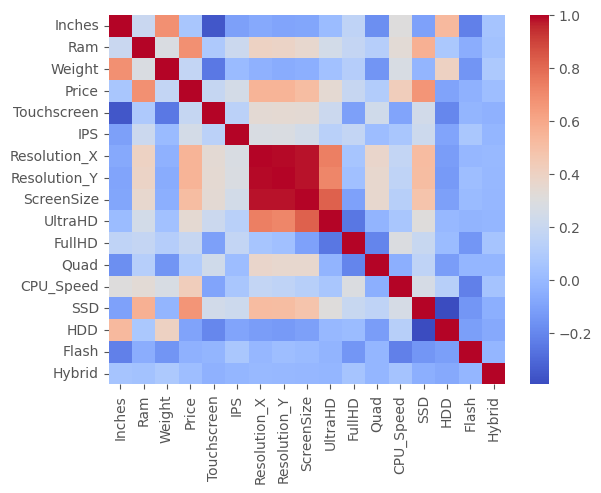

In [89]:
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")

# encoding

In [90]:
df = pd.get_dummies(df, columns=["CPU_Brand", "CPU_Name"], dtype=int)

In [91]:
df = pd.get_dummies(df, columns=["GPU_Brand"], dtype=int)

In [92]:
encoded_OpSys = pd.get_dummies(df["OpSys"], dtype=int)

df = pd.concat([df, encoded_OpSys], axis=1)

In [93]:
df = pd.get_dummies(df, columns=["Company"], dtype=int)

In [94]:
df = pd.get_dummies(df, columns=["TypeName"], dtype=int)

# حذف الاعمده الاصليه

In [95]:
df = df.drop(["ScreenResolution", "Resolution", "Cpu", "Memory", "Gpu", "OpSys"], axis=1)

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1244 entries, 0 to 1273
Data columns (total 60 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Inches                       1244 non-null   float64
 1   Ram                          1244 non-null   int64  
 2   Weight                       1244 non-null   float64
 3   Price                        1244 non-null   float64
 4   Touchscreen                  1244 non-null   int64  
 5   IPS                          1244 non-null   int64  
 6   Resolution_X                 1244 non-null   int64  
 7   Resolution_Y                 1244 non-null   int64  
 8   ScreenSize                   1244 non-null   int64  
 9   UltraHD                      1244 non-null   int64  
 10  FullHD                       1244 non-null   int64  
 11  Quad                         1244 non-null   int64  
 12  CPU_Speed                    1244 non-null   float64
 13  SSD                    

# (Features و Target)تقسيم البيانات

In [97]:
X = df.drop("Price", axis=1) # نحذفه من الداتا عشان احنا نبغا المودل يتوقع السعر
y = df["Price"]   # السعر اللي نبي نتوقعه

#  Train و Test تقسيم

In [98]:
X_train, X_test, y_train, y_test= train_test_split( X, y, test_size=0.2, random_state=42)

# Standard Scaler

In [99]:
#لذلك سويت سكيلينق   linear pca, حساسين للارقام

# اما الراندوم فوريست ما يحتاج لانه يعتمد على تقسيم الشجر مو المسافات بين البيانات

In [100]:
# تصحيح مهم
# قبل كنت أسكل كل الأعمدة بما فيها أعمدة الـ 0 و 1
# مثل Touchscreen و Company_Dell
# وهذا مو صحيح لأن StandardScaler مخصص للأرقام المستمرة
# مو للأعمدة الثنائية اللي قيمها 0 أو 1
# لذلك فصلت الأعمدة المستمرة عن الأعمدة الثنائية
# وسويت Scaling للأعمدة المستمرة فقط

In [101]:
continuous_cols = ["Inches","Ram","CPU_Speed","SSD","HDD","Flash","Hybrid","Weight",
                    "Resolution_X","Resolution_Y","ScreenSize"]

binary_cols = [c for c in X_train.columns if c not in continuous_cols]

scaler = StandardScaler()

X_train_cont = scaler.fit_transform(X_train[continuous_cols])
X_test_cont = scaler.transform(X_test[continuous_cols])

X_train_bin = X_train[binary_cols].values
X_test_bin = X_test[binary_cols].values

# PCA

In [102]:
pca = PCA(n_components=0.95) # variance احتفظ بـ 95% من

X_train_pca_cont = pca.fit_transform(X_train_cont)
X_test_pca_cont = pca.transform(X_test_cont)

In [103]:
print("Number of Components:", pca.n_components_, "from", len(continuous_cols))
print("Total Variance:", pca.explained_variance_ratio_.sum())

Number of Components: 7 from 11
Total Variance: 0.9532117801382147


In [104]:
X_train_final = np.hstack([X_train_pca_cont, X_train_bin])
X_test_final = np.hstack([X_test_pca_cont, X_test_bin])

بعد شوي بشوف هل PCA فعلاً حسّن النتيجة أو لا، بقارن Linear Regression مع PCA مقابل Random Forest بدون PCA في الآخر.

# Linear Regression

In [105]:
lr = LinearRegression()

lr.fit(X_train_final,y_train)

y_pred_lr=lr.predict(X_test_final)

In [106]:
print("MAE =", mean_absolute_error(y_test, y_pred_lr))
print("MSE =", mean_squared_error(y_test, y_pred_lr))
print("R2 =", r2_score(y_test, y_pred_lr))

MAE = 12379.330994956432
MSE = 322427854.631454
R2 = 0.7233631451890532


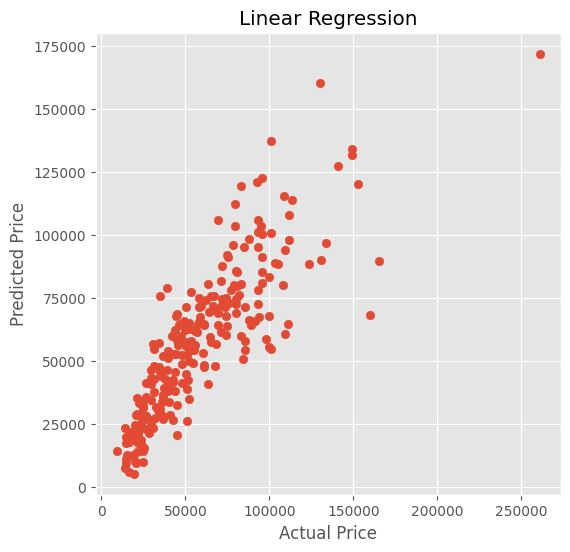

In [107]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred_lr)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression")

plt.show()

# Random Forest

In [108]:
rf2= RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    random_state=42
)

rf2.fit(X_train, y_train)

y_pred_rf2 = rf2.predict(X_test)

print("MAE =", mean_absolute_error(y_test, y_pred_rf2))
print("MSE =", mean_squared_error(y_test, y_pred_rf2))
print("R2 =", r2_score(y_test, y_pred_rf2))

MAE = 9770.53406792947
MSE = 252702183.37781754
R2 = 0.7831864207470401


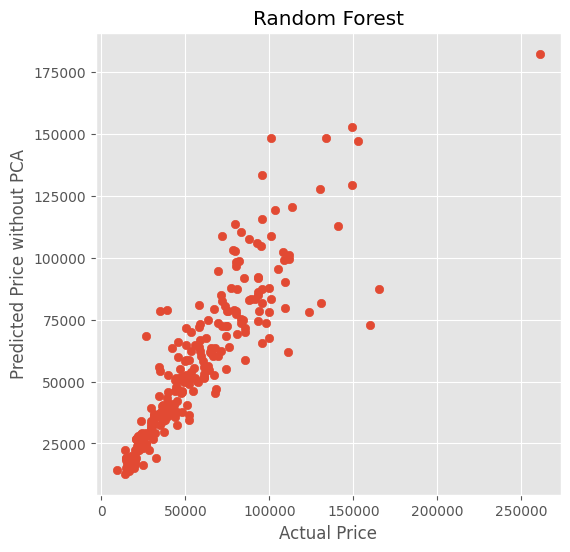

In [109]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred_rf2)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price without PCA")
plt.title("Random Forest")

plt.show()

# Feature Importance

In [110]:
importances = pd.Series(rf2.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10)

,0
Ram,0.532445
Weight,0.110213
CPU_Speed,0.055500
TypeName_Notebook,0.052557
SSD,0.047945
TypeName_Workstation,0.023955
Company_Razer,0.023353
Inches,0.020335
CPU_Name_Core i7,0.014085
CPU_Name_Core i5,0.011858


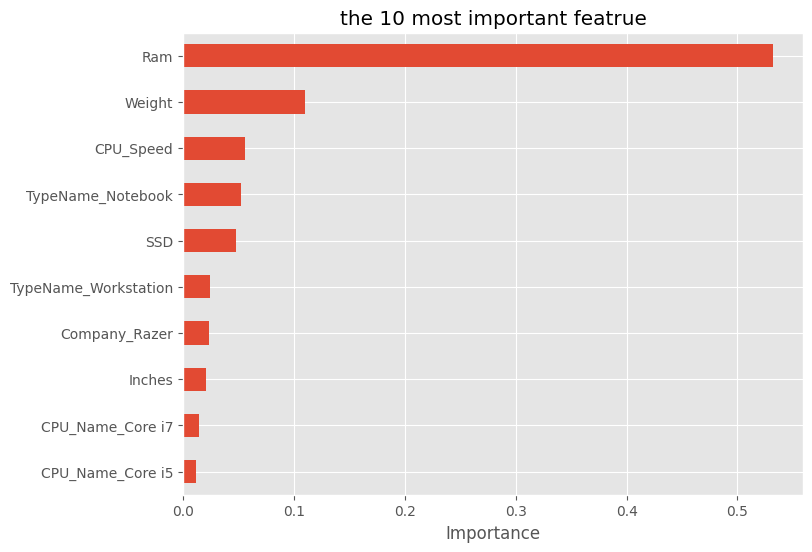

In [111]:
plt.figure(figsize=(8,6))
importances.head(10).sort_values().plot(kind="barh")
plt.title("the 10 most important featrue")
plt.xlabel("Importance")
plt.show()

ram is the feature that havr more effect in the price

In [112]:
print("Linear Regression + PCA :")
print("R2 =", r2_score(y_test, y_pred_lr))
print()
print("Random Forest without PCA:")
print("R2 =", r2_score(y_test, y_pred_rf2))
# Did PCA help?
# Random Forest without PCA gave better results
# PCA did not improve the prediction
# PCA removed some useful information
# Random Forest worked better with the original features
# PCA is more useful when there are many correlated features

Linear Regression + PCA :
R2 = 0.7233631451890532

Random Forest without PCA:
R2 = 0.7831864207470401



## Conclusion

The best model was Random Forest without PCA because it gave the highest R² and the lowest MAE and MSE

This means the relationship between the laptop features and the price is not fully linear

Random Forest can learn more complex patterns so it gave better results than Linear Regression

If I had more time I would use Cross Validation to check if the results stay the same

I would also try Ridge Regression and Lasso Regression

I would tune the Random Forest parameters like max depth and number of trees

I would also check more outliers in the dataset
